# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Rasya Gonawi | 5054251032 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **TensorFlow / Keras** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed dengan tf.keras.utils.set_random_seed(42).
# Cek apakah GPU tersedia dengan tf.config.list_physical_devices("GPU").

import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "1"

from pathlib import Path
import gc
import hashlib
import json
import platform
import shutil
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)
gpus = tf.config.list_physical_devices("GPU")
print("GPU tersedia:" if gpus else "Training menggunakan CPU.", gpus if gpus else "")

Training menggunakan CPU. 


In [2]:
%matplotlib inline
SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 12
LEARNING_RATE = 0.001
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})

ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "fashion"
RESULT_DIR = ROOT / "hasil" / "tugas2"
MODEL_DIR = ROOT / "models" / "tugas2"
WORK_DIR = ROOT / ".runtime" / "tugas2"
for directory in [RESULT_DIR, MODEL_DIR, WORK_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

display(pd.Series({
    "TensorFlow": tf.__version__, "Keras": keras.__version__,
    "Batch size": BATCH_SIZE, "Maksimal epoch": MAX_EPOCHS,
    "Learning rate": LEARNING_RATE,
}, name="Pengaturan eksperimen").to_frame())

,Pengaturan eksperimen
TensorFlow,2.21.0
Keras,3.15.1
Batch size,128
Maksimal epoch,12
Learning rate,0.001


In [3]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_path = DATA_DIR / "fashion-mnist_train.csv"
test_path = DATA_DIR / "fashion-mnist_test.csv"
# uint8 cukup untuk label 0–9 dan piksel 0–255 pada tahap pembacaan.
train_df = pd.read_csv(train_path, dtype="uint8")
test_df = pd.read_csv(test_path, dtype="uint8")
pixel_columns = [column for column in train_df.columns if column != "label"]
assert len(pixel_columns) == 28 * 28
assert train_df.columns.tolist() == test_df.columns.tolist()
assert set(train_df["label"].unique()) == set(range(10))
assert set(test_df["label"].unique()) == set(range(10))
dataset_overview = {
    "train_rows": len(train_df), "test_rows": len(test_df),
    "pixel_columns": len(pixel_columns),
    "train_missing": int(train_df.isna().sum().sum()),
    "test_missing": int(test_df.isna().sum().sum()),
}
display(pd.DataFrame({
    "Bagian": ["Train CSV", "Test CSV"],
    "Bentuk": [str(train_df.shape), str(test_df.shape)],
    "Missing value": [dataset_overview["train_missing"], dataset_overview["test_missing"]],
}).set_index("Bagian"))
display(train_df.iloc[:5, :10])

,Bentuk,Missing value
Bagian,,
Train CSV,"(60000, 785)",0
Test CSV,"(10000, 785)",0


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9
0,2,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0
3,0,0,0,0,1,2,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0


,Kelas,Jumlah,Persentase (%)
0,T-shirt/top,6000,10.0
1,Trouser,6000,10.0
2,Pullover,6000,10.0
3,Dress,6000,10.0
4,Coat,6000,10.0
5,Sandal,6000,10.0
6,Shirt,6000,10.0
7,Sneaker,6000,10.0
8,Bag,6000,10.0
9,Ankle boot,6000,10.0


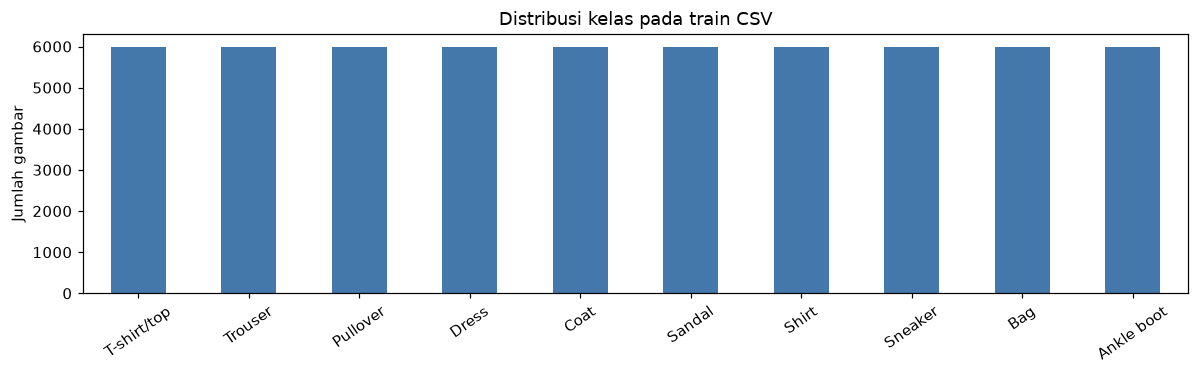

In [4]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]
class_counts = train_df["label"].value_counts().sort_index()
distribution_table = pd.DataFrame({
    "Kelas": class_names, "Jumlah": class_counts.to_numpy(),
    "Persentase (%)": 100 * class_counts.to_numpy() / len(train_df),
})
display(distribution_table)
ax = distribution_table.plot.bar(
    x="Kelas", y="Jumlah", figsize=(11, 3.5), color="#4477aa", legend=False
)
ax.set(title="Distribusi kelas pada train CSV", xlabel="", ylabel="Jumlah gambar")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

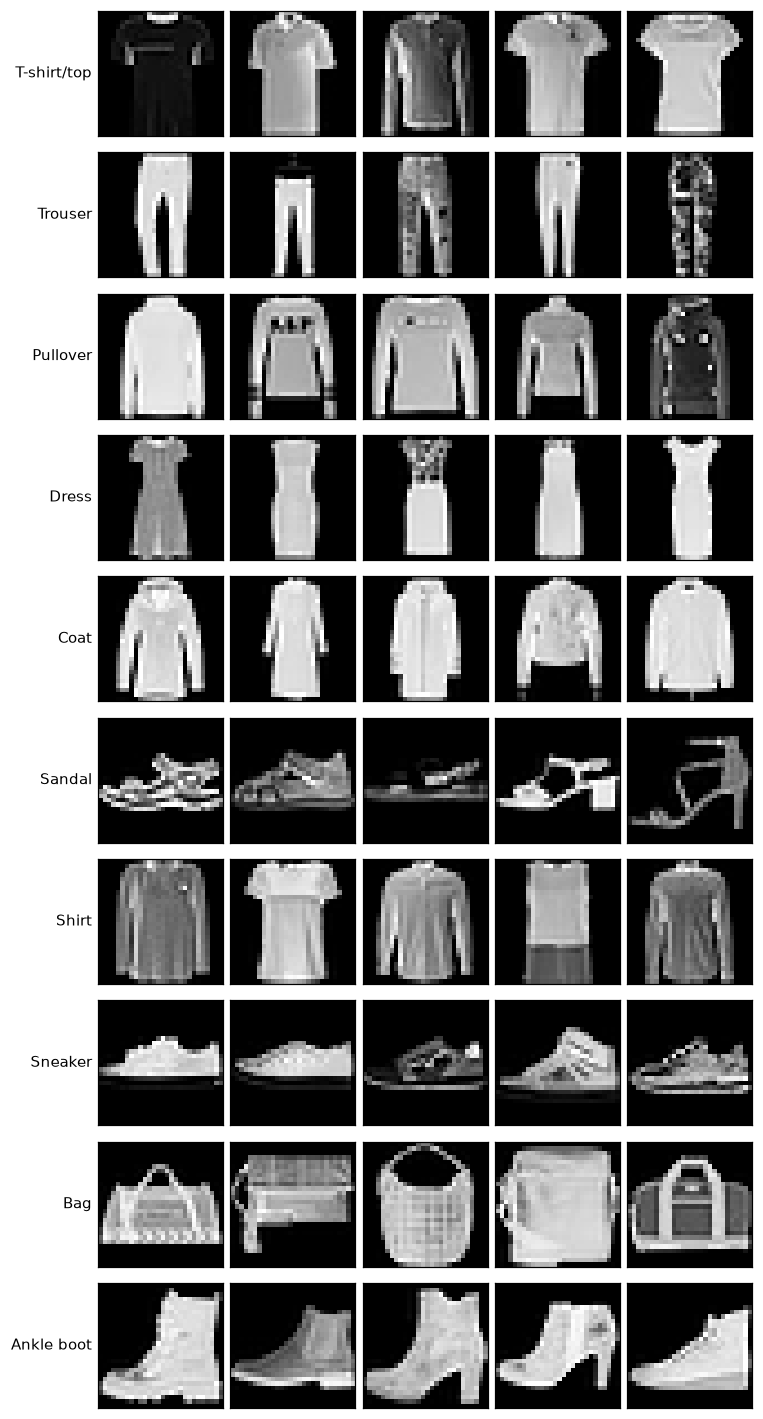

In [5]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

example_rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 5, figsize=(7, 13))
for label in range(10):
    candidates = np.flatnonzero(train_df["label"].to_numpy() == label)
    selected_examples = example_rng.choice(candidates, size=5, replace=False)
    for column, row_index in enumerate(selected_examples):
        image = train_df.iloc[row_index][pixel_columns].to_numpy(dtype="uint8").reshape(28, 28)
        axes[label, column].imshow(image, cmap="gray", vmin=0, vmax=255)
        axes[label, column].set_xticks([])
        axes[label, column].set_yticks([])
        if column == 0:
            axes[label, column].set_ylabel(class_names[label], rotation=0, ha="right", va="center")
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

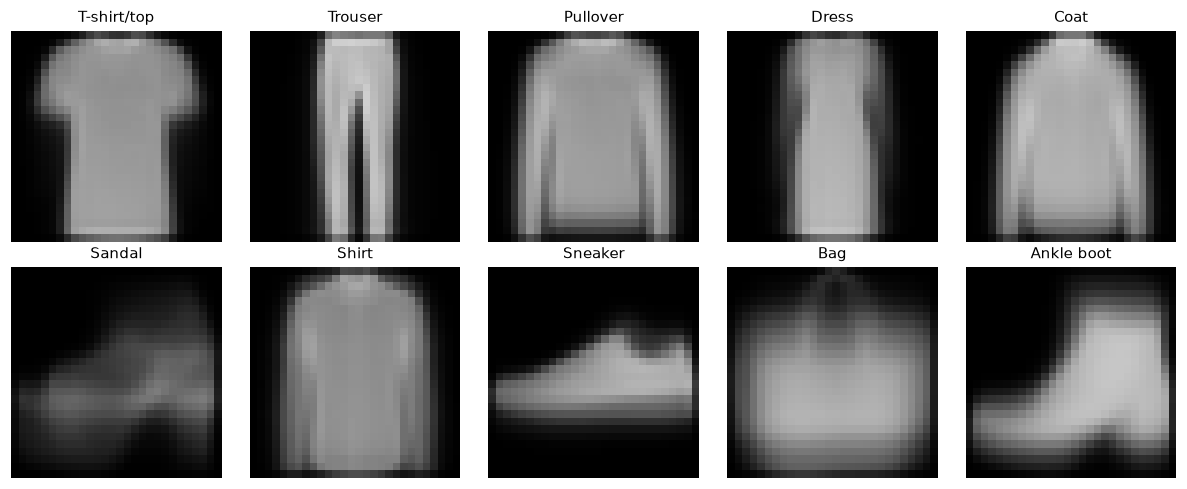

In [6]:
# Rata-rata gambar per kelas memperlihatkan bentuk umum dan area yang sering terisi.
mean_images = []
for label in range(10):
    pixels = train_df.loc[train_df["label"] == label, pixel_columns].to_numpy(dtype="uint8")
    mean_images.append(pixels.mean(axis=0).reshape(28, 28))
del pixels
fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
for label, ax in enumerate(axes.flat):
    ax.imshow(mean_images[label], cmap="gray", vmin=0, vmax=255)
    ax.set_title(class_names[label], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di TensorFlow/Keras, urutan dimensi gambar adalah **(batch, tinggi, lebar, channel)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)` |
| CNN | `(N, 28, 28, 1)` |

In [7]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_full = train_df["label"].to_numpy(dtype="int32", copy=True)
y_test = test_df["label"].to_numpy(dtype="int32", copy=True)
X_full_raw = train_df[pixel_columns].to_numpy(dtype="uint8", copy=False)
X_test_raw = test_df[pixel_columns].to_numpy(dtype="uint8", copy=False)
dataset_overview["pixel_min"] = int(min(X_full_raw.min(), X_test_raw.min()))
dataset_overview["pixel_max"] = int(max(X_full_raw.max(), X_test_raw.max()))
assert dataset_overview["pixel_min"] >= 0 and dataset_overview["pixel_max"] <= 255
del train_df, test_df
gc.collect()
print(f"Piksel dipisahkan dari label; rentang asli "
      f"{dataset_overview['pixel_min']}–{dataset_overview['pixel_max']}.")

Piksel dipisahkan dari label; rentang asli 0–255.


In [8]:
def create_float32_map(filename, shape):
    return np.lib.format.open_memmap(
        WORK_DIR / filename, mode="w+", dtype="float32", shape=shape
    )


def normalize_pixels(raw, filename):
    normalized = create_float32_map(filename, raw.shape)
    for start in range(0, len(raw), 1024):
        end = start + 1024
        normalized[start:end] = raw[start:end].astype("float32") / 255.0
    normalized.flush()
    return normalized

In [9]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_full = normalize_pixels(X_full_raw, "all_train_normalized.npy")
X_test = normalize_pixels(X_test_raw, "test_normalized.npy")
del X_full_raw, X_test_raw
gc.collect()
print(f"Rentang piksel setelah normalisasi: {X_full.min():.1f}–{X_full.max():.1f}; "
      f"dtype: {X_full.dtype}.")

Rentang piksel setelah normalisasi: 0.0–1.0; dtype: float32.


In [10]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

train_indices, val_indices = train_test_split(
    np.arange(len(y_full)), test_size=0.10, stratify=y_full, random_state=SEED
)
assert set(train_indices).isdisjoint(val_indices)
y_train, y_val = y_full[train_indices], y_full[val_indices]
X_train = create_float32_map("train_normalized.npy", (len(train_indices), 784))
X_val = create_float32_map("val_normalized.npy", (len(val_indices), 784))
for output, indices in [(X_train, train_indices), (X_val, val_indices)]:
    for start in range(0, len(indices), 1024):
        output[start:start + 1024] = X_full[indices[start:start + 1024]]
    output.flush()
del X_full, y_full, output
gc.collect()
split_table = pd.DataFrame({
    "Training": np.bincount(y_train, minlength=10),
    "Validation": np.bincount(y_val, minlength=10),
    "Test": np.bincount(y_test, minlength=10),
}, index=class_names)
display(split_table)

,Training,Validation,Test
T-shirt/top,5400,600,1000
Trouser,5400,600,1000
Pullover,5400,600,1000
Dress,5400,600,1000
Coat,5400,600,1000
Sandal,5400,600,1000
Shirt,5400,600,1000
Sneaker,5400,600,1000
Bag,5400,600,1000
Ankle boot,5400,600,1000


In [11]:
# Ubah bentuk data sesuai kebutuhan model (lihat tabel di atas), pastikan bertipe float32.
# Contoh untuk CNN: X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")

X_train_ann, X_val_ann, X_test_ann = X_train, X_val, X_test
# reshape membuat view; tidak menambah salinan besar dari piksel yang sama.
X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_val_cnn = X_val.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)
assert all(array.dtype == np.float32 for array in [X_train_ann, X_val_ann, X_test_ann,
                                                   X_train_cnn, X_val_cnn, X_test_cnn])
display(pd.DataFrame({
    "Bagian": ["Training", "Validation", "Test"],
    "Input ANN": [str(X_train_ann.shape), str(X_val_ann.shape), str(X_test_ann.shape)],
    "Input CNN": [str(X_train_cnn.shape), str(X_val_cnn.shape), str(X_test_cnn.shape)],
    "Tipe data": [str(X_train.dtype), str(X_val.dtype), str(X_test.dtype)],
}).set_index("Bagian"))

,Input ANN,Input CNN,Tipe data
Bagian,,,
Training,"(54000, 784)","(54000, 28, 28, 1)",float32
Validation,"(6000, 784)","(6000, 28, 28, 1)",float32
Test,"(10000, 784)","(10000, 28, 28, 1)",float32


In [12]:
def make_dataset(features, labels, shuffle=False):
    rng = np.random.default_rng(SEED)

    def batches():
        order = rng.permutation(len(labels)) if shuffle else np.arange(len(labels))
        for start in range(0, len(order), BATCH_SIZE):
            indices = order[start:start + BATCH_SIZE]
            yield np.asarray(features[indices], dtype="float32"), labels[indices]

    dataset = tf.data.Dataset.from_generator(
        batches, output_signature=(
            tf.TensorSpec(shape=(None, *features.shape[1:]), dtype=tf.float32),
            tf.TensorSpec(shape=(None,), dtype=tf.int32),
        ),
    )
    dataset = dataset.apply(tf.data.experimental.assert_cardinality(
        (len(labels) + BATCH_SIZE - 1) // BATCH_SIZE
    ))
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    options.deterministic = True
    return dataset.with_options(options).prefetch(1)

# 3. Eksperimen Model

In [13]:
def metric_values(target, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(
        target, predicted, labels=np.arange(10), average="macro", zero_division=0
    )
    return {"Accuracy": accuracy_score(target, predicted),
            "Precision_macro": precision, "Recall_macro": recall, "F1_macro": f1}


candidate_paths = {
    "ANN": WORK_DIR / "ann.keras",
    "CNN sederhana": WORK_DIR / "cnn.keras",
    "CNN + BN + Dropout": WORK_DIR / "cnn_bn_dropout.keras",
}
progress_paths = {
    name: WORK_DIR / f"progress_{index}.csv"
    for index, name in enumerate(candidate_paths)
}
histories, parameter_counts, validation_scores = {}, {}, {}
test_probabilities, test_predictions, training_seconds = {}, {}, {}

In [14]:
class EpochTimer(keras.callbacks.Callback):
    def on_epoch_begin(self, epoch, logs=None):
        self.started = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        logs["epoch_seconds"] = time.perf_counter() - self.started


def training_callbacks(name):
    return [
        EpochTimer(),
        keras.callbacks.EarlyStopping(
            monitor="val_loss", mode="min", patience=3, restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(candidate_paths[name]), monitor="val_loss", mode="min",
            save_best_only=True, verbose=0,
        ),
        keras.callbacks.CSVLogger(str(progress_paths[name])),
    ]

In [15]:
def register_model(name, model, history, validation_data, elapsed):
    values = history.history
    histories[name] = values
    training_seconds[name] = elapsed
    parameter_counts[name] = {
        "total": int(model.count_params()),
        "trainable": int(sum(np.prod(weight.shape) for weight in model.trainable_weights)),
        "non_trainable": int(sum(np.prod(weight.shape) for weight in model.non_trainable_weights)),
    }
    probabilities = model.predict(validation_data, verbose=0)
    assert probabilities.shape == (len(y_val), 10) and np.isfinite(probabilities).all()
    np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-5)
    validation_scores[name] = metric_values(y_val, probabilities.argmax(axis=1))
    display(pd.DataFrame([{
        "Model": name, "Epoch": len(values["loss"]),
        "Epoch terbaik": int(np.argmin(values["val_loss"]) + 1),
        "Parameter": parameter_counts[name]["total"], **validation_scores[name],
    }]).set_index("Model").round(4))

In [16]:
def plot_history(name):
    values = histories[name]
    epochs = np.arange(1, len(values["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    best_epoch = int(np.argmin(values["val_loss"]) + 1)
    for ax, train_key, val_key, ylabel in [
        (axes[0], "loss", "val_loss", "Cross-entropy"),
        (axes[1], "accuracy", "val_accuracy", "Accuracy"),
    ]:
        ax.plot(epochs, values[train_key], label="Training", color="#4477aa")
        ax.plot(epochs, values[val_key], label="Validation", color="#ee7733")
        ax.axvline(best_epoch, linestyle=":", color="gray", label="Epoch terbaik")
        ax.set(xlabel="Epoch", ylabel=ylabel)
        ax.grid(alpha=0.2)
        ax.legend()
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output dengan aktivasi Softmax** dan **`sparse_categorical_crossentropy`** sebagai loss function (label berupa angka 0-9).

Contoh arsitektur: `Input(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax)`

In [17]:
# Definisikan arsitektur ANN menggunakan keras.Sequential.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().

tf.keras.utils.set_random_seed(SEED)
ann_model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="ann_baseline")
ann_model.summary()

Model: "ann_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
# Compile model dengan optimizer, loss="sparse_categorical_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit() menggunakan validation_data, simpan hasilnya ke variabel history.

ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"],
)
ann_train_data = make_dataset(X_train_ann, y_train, shuffle=True)
ann_val_data = make_dataset(X_val_ann, y_val)
started = time.perf_counter()
history = ann_model.fit(
    ann_train_data, validation_data=ann_val_data, epochs=MAX_EPOCHS,
    callbacks=training_callbacks("ANN"), verbose=0,
)
register_model("ANN", ann_model, history, ann_val_data, time.perf_counter() - started)

D:\KULIAH\Material\Semester 3\Machine Learning\ML-Tugas\9. CNN\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,Epoch,Epoch terbaik,Parameter,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,,,,
ANN,12,11,235146,0.8897,0.8898,0.8897,0.8893


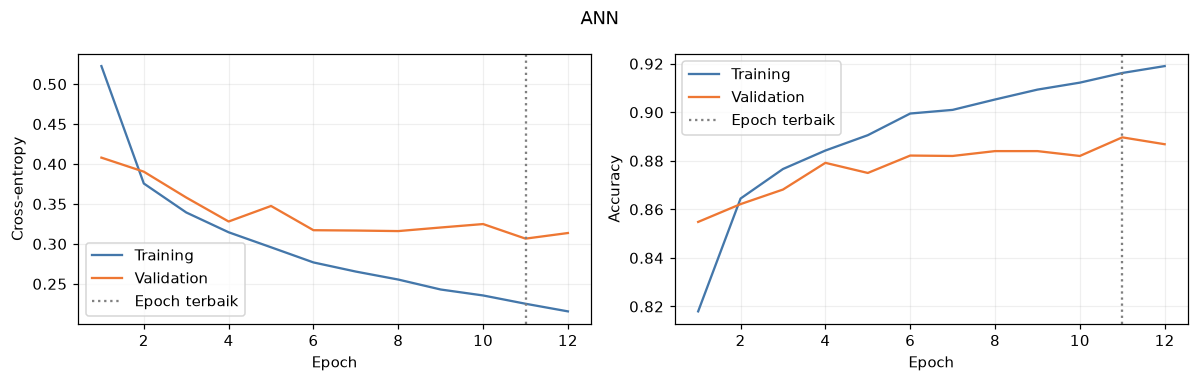

In [19]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

plot_history("ANN")

In [20]:
# Lakukan prediksi pada test set. model.predict() menghasilkan probabilitas 10 kelas,
# ambil kelas dengan probabilitas terbesar menggunakan argmax(axis=1). Simpan hasil prediksi label.

test_probabilities["ANN"] = ann_model.predict(
    make_dataset(X_test_ann, y_test), verbose=0
)
test_predictions["ANN"] = test_probabilities["ANN"].argmax(axis=1)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2D (ReLU) → MaxPooling, lalu dilanjutkan Flatten dan Dense.

Contoh arsitektur: `[Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2)] → [Conv2D(64, 3×3, ReLU) → MaxPooling2D(2×2)] → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`

In [21]:
# Definisikan arsitektur CNN sederhana menggunakan layers.Conv2D, layers.MaxPooling2D, layers.Flatten, dan layers.Dense.
# Gunakan keras.Input(shape=(28, 28, 1)) sebagai layer pertama.
# Tampilkan ringkasan model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1,
# lalu cocokkan dengan kolom "Output Shape" pada model.summary(). (padding="valid" berarti P = 0, padding="same" menjaga ukuran tetap)

del ann_model, history
keras.backend.clear_session()
gc.collect()
tf.keras.utils.set_random_seed(SEED)
cnn_model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu", padding="valid"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu", padding="valid"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="cnn_sederhana")
cnn_model.summary()

Model: "cnn_sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
# Untuk output yang tidak bulat, gunakan floor seperti pada pooling valid.
def output_width(width, kernel, padding=0, stride=1):
    return (width - kernel + 2 * padding) // stride + 1


conv1 = output_width(28, 3)
pool1 = output_width(conv1, 2, stride=2)
conv2 = output_width(pool1, 3)
pool2 = output_width(conv2, 2, stride=2)
manual_shapes = [(None, conv1, conv1, 32), (None, pool1, pool1, 32),
                 (None, conv2, conv2, 64), (None, pool2, pool2, 64),
                 (None, pool2 * pool2 * 64), (None, 128), (None, 10)]
formulae = ["(28−3)/1+1 = 26", "(26−2)/2+1 = 13",
            "(13−3)/1+1 = 11", "floor((11−2)/2+1) = 5",
            "5 × 5 × 64 = 1600", "128 neuron", "10 kelas"]
manual_shape_table = pd.DataFrame([
    {"Layer": layer.name, "Perhitungan": formula,
     "Shape manual": str(expected), "Shape Keras": str(tuple(layer.output.shape)),
     "Sesuai": expected == tuple(layer.output.shape)}
    for layer, expected, formula in zip(cnn_model.layers, manual_shapes, formulae)
])
assert manual_shape_table["Sesuai"].all()
display(manual_shape_table)

,Layer,Perhitungan,Shape manual,Shape Keras,Sesuai
0,conv2d,(28−3)/1+1 = 26,"(None, 26, 26, 32)","(None, 26, 26, 32)",True
1,max_pooling2d,(26−2)/2+1 = 13,"(None, 13, 13, 32)","(None, 13, 13, 32)",True
2,conv2d_1,(13−3)/1+1 = 11,"(None, 11, 11, 64)","(None, 11, 11, 64)",True
3,max_pooling2d_1,floor((11−2)/2+1) = 5,"(None, 5, 5, 64)","(None, 5, 5, 64)",True
4,flatten,5 × 5 × 64 = 1600,"(None, 1600)","(None, 1600)",True
5,dense,128 neuron,"(None, 128)","(None, 128)",True
6,dense_1,10 kelas,"(None, 10)","(None, 10)",True


D:\KULIAH\Material\Semester 3\Machine Learning\ML-Tugas\9. CNN\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,Epoch,Epoch terbaik,Parameter,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,,,,
CNN sederhana,12,10,225034,0.9087,0.9108,0.9087,0.9092


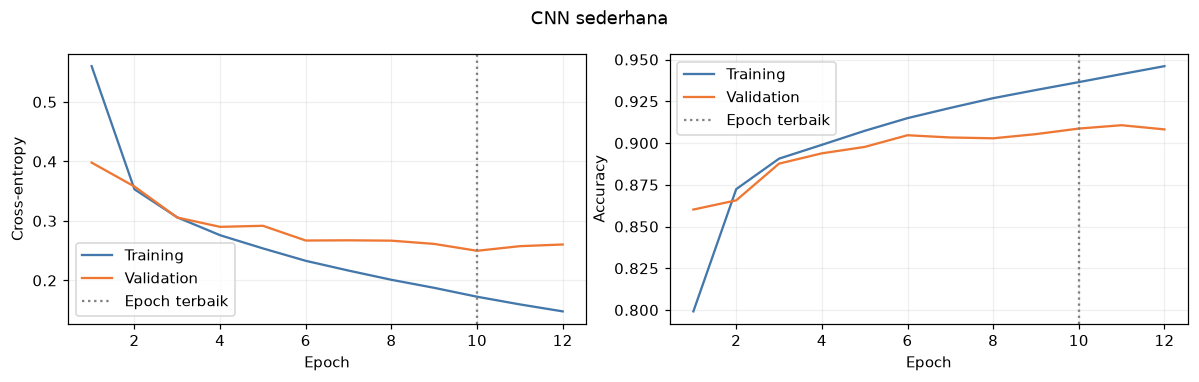

In [23]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"],
)
cnn_train_data = make_dataset(X_train_cnn, y_train, shuffle=True)
cnn_val_data = make_dataset(X_val_cnn, y_val)
started = time.perf_counter()
history_cnn = cnn_model.fit(
    cnn_train_data, validation_data=cnn_val_data, epochs=MAX_EPOCHS,
    callbacks=training_callbacks("CNN sederhana"), verbose=0,
)
register_model("CNN sederhana", cnn_model, history_cnn, cnn_val_data,
               time.perf_counter() - started)
plot_history("CNN sederhana")

In [24]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

test_probabilities["CNN sederhana"] = cnn_model.predict(
    make_dataset(X_test_cnn, y_test), verbose=0
)
test_predictions["CNN sederhana"] = test_probabilities["CNN sederhana"].argmax(axis=1)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [25]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: Conv2D (tanpa activation) -> layers.BatchNormalization() -> layers.Activation("relu") -> MaxPooling2D.
# Tambahkan layers.Dropout(rate) sebelum layer output.
# Tampilkan ringkasan model beserta jumlah parameternya.

del cnn_model, history_cnn
keras.backend.clear_session()
gc.collect()
tf.keras.utils.set_random_seed(SEED)
cnn_bn_model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), padding="valid"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), padding="valid"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation="softmax"),
], name="cnn_bn_dropout")
cnn_bn_model.summary()

Model: "cnn_bn_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

D:\KULIAH\Material\Semester 3\Machine Learning\ML-Tugas\9. CNN\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,Epoch,Epoch terbaik,Parameter,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,,,,
CNN + BN + Dropout,12,9,225418,0.9097,0.9098,0.9097,0.9096


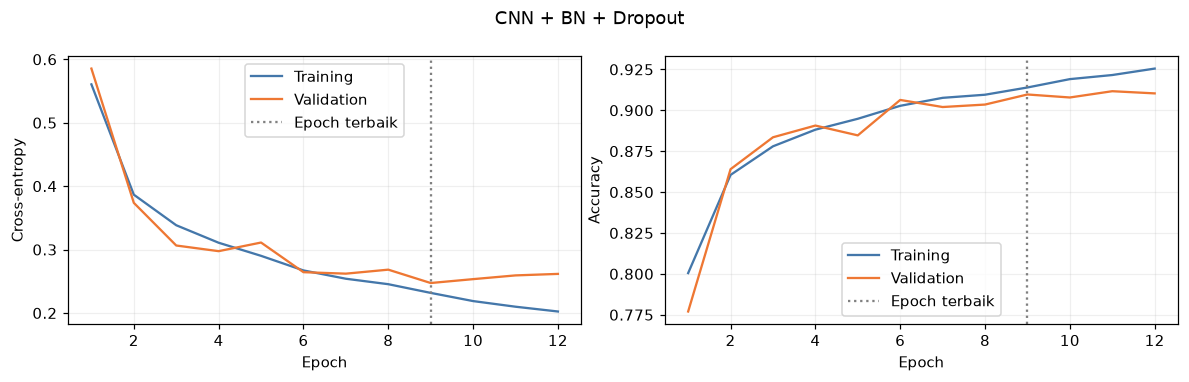

In [26]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

cnn_bn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy", metrics=["accuracy"],
)
# Buat ulang dataset agar urutan pengacakan kembali dimulai dari seed yang sama.
bn_train_data = make_dataset(X_train_cnn, y_train, shuffle=True)
bn_val_data = make_dataset(X_val_cnn, y_val)
started = time.perf_counter()
history_bn = cnn_bn_model.fit(
    bn_train_data, validation_data=bn_val_data, epochs=MAX_EPOCHS,
    callbacks=training_callbacks("CNN + BN + Dropout"), verbose=0,
)
register_model("CNN + BN + Dropout", cnn_bn_model, history_bn, bn_val_data,
               time.perf_counter() - started)
plot_history("CNN + BN + Dropout")

In [27]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

test_probabilities["CNN + BN + Dropout"] = cnn_bn_model.predict(
    make_dataset(X_test_cnn, y_test), verbose=0
)
test_predictions["CNN + BN + Dropout"] = test_probabilities["CNN + BN + Dropout"].argmax(axis=1)

# 4. Evaluasi Model

In [28]:
# Pilih model dari validation sebelum membuka metrik test.
validation_table = pd.DataFrame.from_dict(validation_scores, orient="index")
validation_table.index.name = "Model"
validation_ranking = validation_table.sort_values(
    ["F1_macro", "Accuracy"], ascending=False, kind="stable"
)
best_name = str(validation_ranking.index[0])
display(validation_ranking.round(4))
print(f"Model terpilih berdasarkan F1 macro validation: {best_name}")
del cnn_bn_model, history_bn
keras.backend.clear_session()
gc.collect()
best_model = keras.models.load_model(candidate_paths[best_name])

,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,
CNN + BN + Dropout,0.9097,0.9098,0.9097,0.9096
CNN sederhana,0.9087,0.9108,0.9087,0.9092
ANN,0.8897,0.8898,0.8897,0.8893


Model terpilih berdasarkan F1 macro validation: CNN + BN + Dropout


In [29]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

test_scores = {
    name: metric_values(y_test, predicted)
    for name, predicted in test_predictions.items()
}
test_table = pd.DataFrame.from_dict(test_scores, orient="index")
test_table.index.name = "Model"
test_table["Parameters"] = [parameter_counts[name]["total"] for name in test_table.index]
display(test_table.round(4))

,Accuracy,Precision_macro,Recall_macro,F1_macro,Parameters
Model,,,,,
ANN,0.8948,0.8947,0.8948,0.8942,235146
CNN sederhana,0.9168,0.9182,0.9168,0.9171,225034
CNN + BN + Dropout,0.9132,0.9134,0.9132,0.9131,225418


In [30]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

best_predictions = test_predictions[best_name]
best_report = classification_report(
    y_test, best_predictions, labels=np.arange(10), target_names=class_names,
    output_dict=True, zero_division=0,
)
report_table = pd.DataFrame(best_report).transpose()
display(report_table.round(4))

,precision,recall,f1-score,support
T-shirt/top,0.8292,0.8690,0.8486,1000.0000
Trouser,0.9880,0.9850,0.9865,1000.0000
Pullover,0.9022,0.8490,0.8748,1000.0000
Dress,0.9257,0.9340,0.9298,1000.0000
Coat,0.8712,0.8790,0.8751,1000.0000
Sandal,0.9907,0.9570,0.9736,1000.0000
Shirt,0.7541,0.7420,0.7480,1000.0000
Sneaker,0.9512,0.9550,0.9531,1000.0000
Bag,0.9801,0.9850,0.9825,1000.0000
Ankle boot,0.9421,0.9770,0.9593,1000.0000


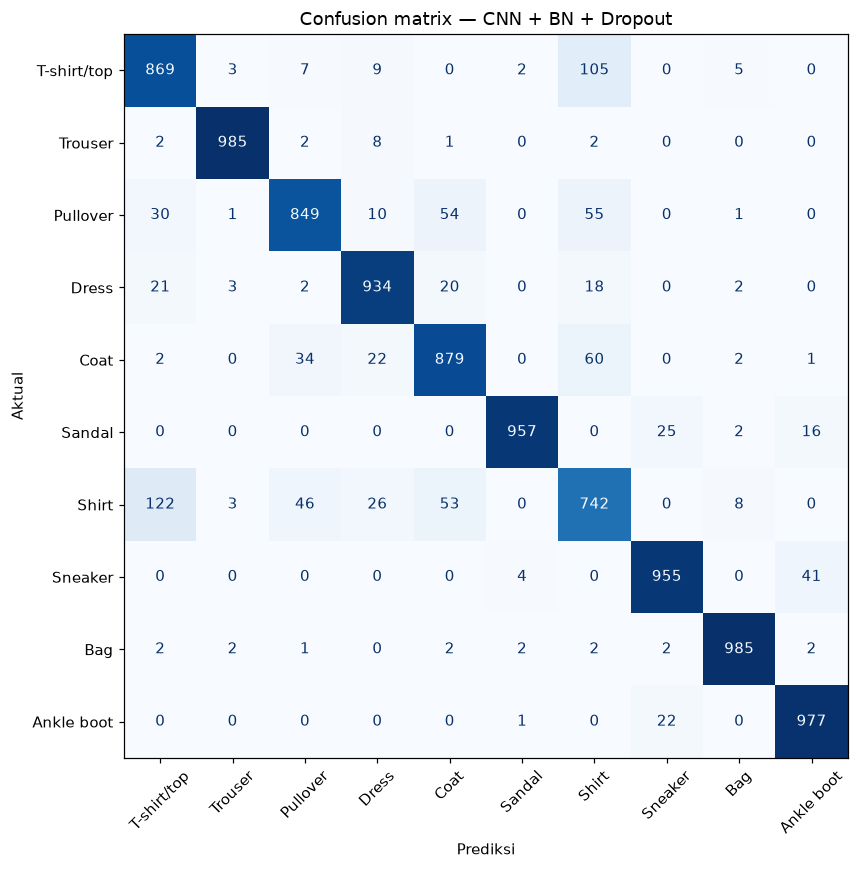

,Aktual,Prediksi,Jumlah
0,Shirt,T-shirt/top,122
1,T-shirt/top,Shirt,105
2,Coat,Shirt,60
3,Pullover,Shirt,55
4,Pullover,Coat,54


In [31]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

best_cm = confusion_matrix(y_test, best_predictions, labels=np.arange(10))
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(best_cm, display_labels=class_names).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d", xticks_rotation=45
)
ax.set(title=f"Confusion matrix — {best_name}", xlabel="Prediksi", ylabel="Aktual")
plt.tight_layout()
plt.show()

confused_pairs = pd.DataFrame([
    {"Aktual": class_names[actual], "Prediksi": class_names[predicted],
     "Jumlah": int(best_cm[actual, predicted])}
    for actual in range(10) for predicted in range(10) if actual != predicted
]).sort_values("Jumlah", ascending=False).head(5)
display(confused_pairs.reset_index(drop=True))

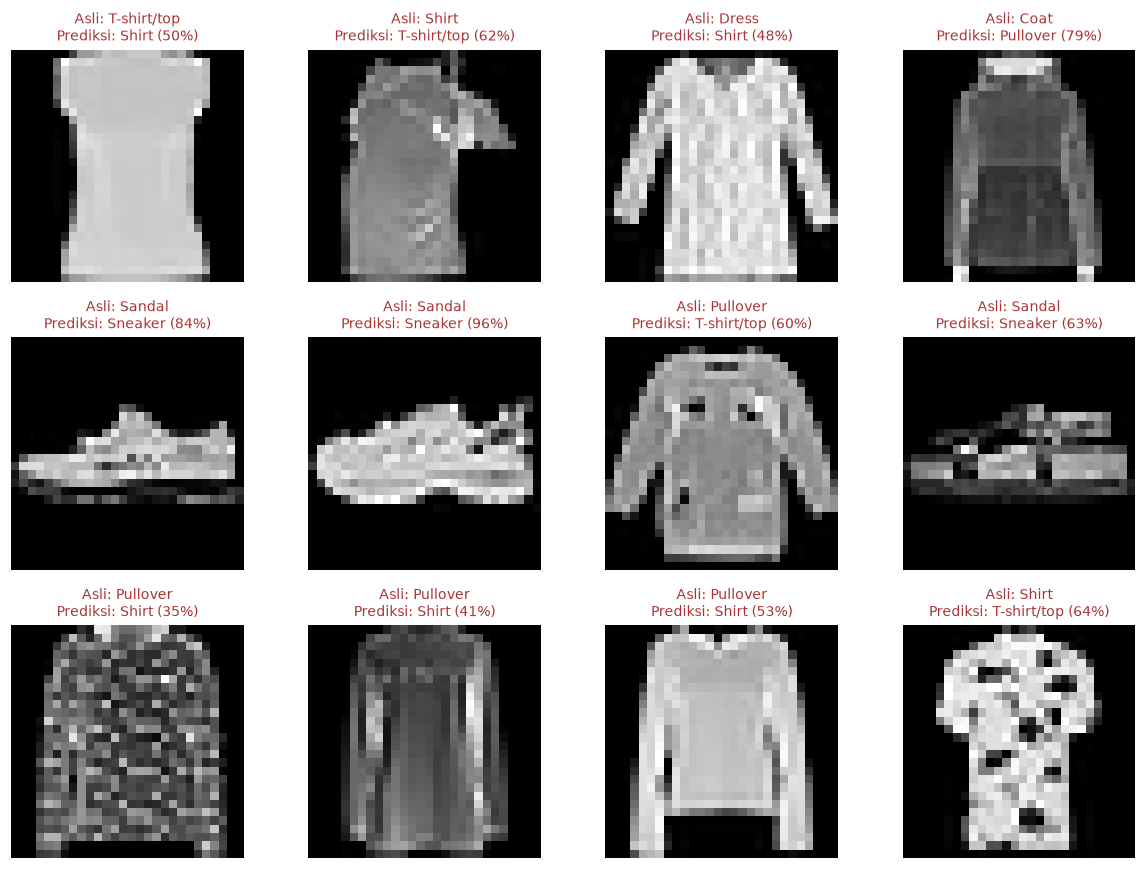

In [32]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

error_indices = np.flatnonzero(best_predictions != y_test)
chosen_errors = np.random.default_rng(SEED).choice(
    error_indices, size=min(12, len(error_indices)), replace=False
)
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for ax, index in zip(axes.flat, chosen_errors):
    ax.imshow(X_test_cnn[index, :, :, 0], cmap="gray", vmin=0, vmax=1)
    confidence = test_probabilities[best_name][index, best_predictions[index]]
    ax.set_title(f"Asli: {class_names[y_test[index]]}\n"
                 f"Prediksi: {class_names[best_predictions[index]]} ({confidence:.0%})",
                 fontsize=9, color="#aa3333")
    ax.axis("off")
for ax in list(axes.flat)[len(chosen_errors):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

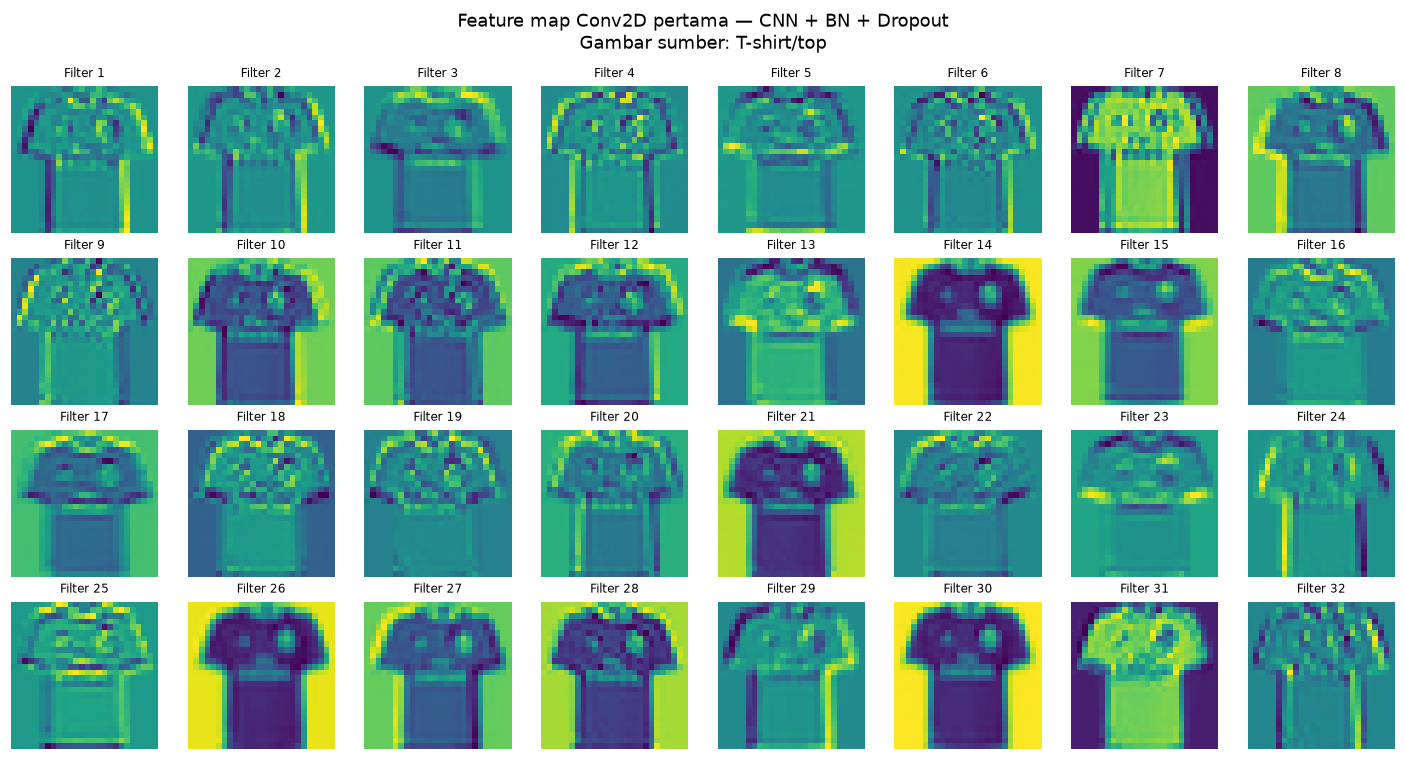

In [33]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Buat model baru yang output-nya adalah output layer konvolusi pertama:
#   feature_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
# lalu tampilkan setiap channel hasil feature_model.predict() sebagai gambar.
# Apa saja pola yang ditangkap oleh masing-masing filter?

feature_source_name = best_name
if not any(isinstance(layer, layers.Conv2D) for layer in best_model.layers):
    # Jika ANN menang, gunakan CNN terbaik hanya untuk visualisasi konvolusi.
    feature_source_name = next(name for name in validation_ranking.index if name != "ANN")
feature_source = (best_model if feature_source_name == best_name
                  else keras.models.load_model(candidate_paths[feature_source_name]))
first_conv = next(layer for layer in feature_source.layers if isinstance(layer, layers.Conv2D))
feature_model = keras.Model(inputs=feature_source.inputs[0], outputs=first_conv.output)
sample_index = 0
sample_image = X_test_cnn[sample_index:sample_index + 1]
feature_maps = feature_model.predict(sample_image, verbose=0)[0]
fig, axes = plt.subplots(4, 8, figsize=(13, 7))
for channel, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[:, :, channel], cmap="viridis")
    ax.set_title(f"Filter {channel + 1}", fontsize=8)
    ax.axis("off")
fig.suptitle(f"Feature map Conv2D pertama — {feature_source_name}\n"
             f"Gambar sumber: {class_names[y_test[sample_index]]}")
plt.tight_layout()
plt.show()

In [34]:
# Simpan model terbaik dengan model.save("model.keras").
# Model ini akan digunakan kembali pada tugas Deployment.

model_path = MODEL_DIR / "model_terbaik.keras"
best_model.save(model_path)
reloaded_model = keras.models.load_model(model_path)
sample_input = X_test_ann[:10] if best_name == "ANN" else X_test_cnn[:10]
reloaded_probabilities = reloaded_model.predict(sample_input, verbose=0)
np.testing.assert_allclose(
    reloaded_probabilities, test_probabilities[best_name][:10], rtol=1e-4, atol=1e-5
)
np.testing.assert_array_equal(reloaded_probabilities.argmax(axis=1), best_predictions[:10])
print(f"Model disimpan: {model_path.relative_to(ROOT)}")
print("Model berhasil dimuat ulang; probabilitas dan kelas prediksi konsisten.")
del reloaded_model
gc.collect()

Model disimpan: models\tugas2\model_terbaik.keras
Model berhasil dimuat ulang; probabilitas dan kelas prediksi konsisten.


54278

In [35]:
curve_rows = []
for name, values in histories.items():
    i = int(np.argmin(values["val_loss"]))
    curve_rows.append({
        "Model": name, "Epoch terbaik": i + 1, "Epoch dijalankan": len(values["loss"]),
        "Train loss (terbaik)": values["loss"][i],
        "Val loss (terbaik)": values["val_loss"][i],
        "Train accuracy (terbaik)": values["accuracy"][i],
        "Val accuracy (terbaik)": values["val_accuracy"][i],
        "Train loss (akhir)": values["loss"][-1],
        "Val loss (akhir)": values["val_loss"][-1],
        "Train accuracy (akhir)": values["accuracy"][-1],
        "Val accuracy (akhir)": values["val_accuracy"][-1],
    })
curve_table = pd.DataFrame(curve_rows).set_index("Model")
display(curve_table.round(4))

,Epoch terbaik,Epoch dijalankan,Train loss (terbaik),Val loss (terbaik),Train accuracy (terbaik),Val accuracy (terbaik),Train loss (akhir),Val loss (akhir),Train accuracy (akhir),Val accuracy (akhir)
Model,,,,,,,,,,
ANN,11,12,0.2251,0.3066,0.9162,0.8897,0.2156,0.3136,0.9190,0.8868
CNN sederhana,10,12,0.1726,0.2498,0.9365,0.9087,0.1479,0.2604,0.9460,0.9082
CNN + BN + Dropout,9,12,0.2317,0.2473,0.9139,0.9097,0.2024,0.2617,0.9255,0.9103


In [36]:
def file_sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


metadata = {
    "student": {"name": "Rasya Gonawi", "nrp": "5054251032"},
    "selected_model": best_name, "model_file": model_path.name,
    "selection_rule": "Maximum validation F1_macro; Accuracy as tie breaker",
    "input_shape": [784] if best_name == "ANN" else [28, 28, 1],
    "preprocessing": {"dtype": "float32", "normalization": "pixel / 255.0",
                      "source_pixel_range": [0, 255], "channels": "grayscale"},
    "prediction_rule": "argmax of 10 softmax probabilities",
    "class_names": class_names, "seed": SEED,
    "split": {"train": len(y_train), "validation": len(y_val), "test": len(y_test)},
    "training": {"max_epochs": MAX_EPOCHS, "batch_size": BATCH_SIZE,
                 "learning_rate": LEARNING_RATE, "early_stopping_patience": 3,
                 "device": "GPU" if gpus else "CPU", "augmentation": False},
    "validation_metrics": validation_scores[best_name], "test_metrics": test_scores[best_name],
    "dataset_sha256": {train_path.name: file_sha256(train_path), test_path.name: file_sha256(test_path)},
    "template_sha256": file_sha256(ROOT / "2_DL_NRP.ipynb"),
    "versions": {"python": platform.python_version(), "tensorflow": tf.__version__,
                 "keras": keras.__version__, "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "reload_check": "passed on 10 test rows: probabilities and argmax labels",
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
(MODEL_DIR / "class_names.json").write_text(json.dumps(class_names, indent=2), encoding="utf-8")

128

In [37]:
(MODEL_DIR / "requirements.txt").write_text(
    "\n".join(f"{name}=={version}" for name, version in metadata["versions"].items()
              if name in ["tensorflow", "keras", "numpy"]) + "\n", encoding="utf-8"
)
pd.concat({"Validation": validation_table, "Test": test_table},
          names=["Bagian", "Model"]).to_csv(RESULT_DIR / "perbandingan_model.csv")
pd.concat([
    pd.DataFrame(values).assign(Model=name, Epoch=lambda table: np.arange(1, len(table) + 1))
    for name, values in histories.items()
], ignore_index=True).to_csv(RESULT_DIR / "riwayat_training.csv", index=False)
report_table.to_csv(RESULT_DIR / "classification_report.csv")
pd.DataFrame(best_cm, index=class_names, columns=class_names).to_csv(RESULT_DIR / "confusion_matrix.csv")

experiment_results = {
    **metadata, "all_validation_metrics": validation_scores, "all_test_metrics": test_scores,
    "parameter_counts": parameter_counts, "training_seconds": training_seconds,
    "ann_curve_summary": curve_table.reset_index().to_dict(orient="records"),
    "dataset_overview": dataset_overview, "class_distribution": class_counts.to_dict(),
    "classification_report": best_report, "confusion_matrix": best_cm.tolist(),
    "top_confusions": confused_pairs.to_dict(orient="records"),
    "total_errors": int(len(error_indices)), "shown_error_indices": chosen_errors.tolist(),
    "feature_map_source_model": feature_source_name, "feature_map_shape": list(feature_maps.shape),
    "feature_map_sample_class": class_names[int(y_test[sample_index])],
    "manual_conv_shapes": manual_shape_table.to_dict(orient="records"),
}
(RESULT_DIR / "hasil_eksperimen.json").write_text(
    json.dumps(experiment_results, indent=2, ensure_ascii=False), encoding="utf-8"
)
display(pd.DataFrame({"File model": [str(path.relative_to(ROOT)) for path in sorted(MODEL_DIR.iterdir())]}))

,File model
0,models\tugas2\class_names.json
1,models\tugas2\metadata.json
2,models\tugas2\model_terbaik.keras
3,models\tugas2\requirements.txt


# 5. Analisis dan Kesimpulan

Eksperimen menggunakan 54.000 gambar training, 6.000 validation, dan 10.000 test dengan kelas yang seimbang. ANN memperoleh accuracy test 89,48% dan F1 macro 0,8942. CNN sederhana meningkat menjadi 91,68% dan 0,9171, sedangkan CNN + BN + Dropout memperoleh 91,32% dan 0,9131.

CNN sederhana memiliki 225.034 parameter, lebih sedikit daripada ANN dengan 235.146 parameter, tetapi hasilnya lebih baik. Filter lokal dan pembagian bobot membantu CNN mempelajari pola spasial gambar. CNN + BN + Dropout memiliki 225.418 parameter; tambahan parameter berasal dari Batch Normalization, sedangkan Dropout tidak menambah bobot.

Loss validation terendah ANN terjadi pada epoch 11 (0,3066), CNN sederhana pada epoch 10 (0,2498), dan CNN + BN + Dropout pada epoch 9 (0,2473). Pada akhir training, loss training terus turun tetapi validation memburuk, sehingga terlihat gejala overfitting. Gap kurva model dengan regularisasi lebih kecil, tetapi mode training dan validation berbeda karena Dropout dan Batch Normalization. Pada percobaan ini regularisasi belum meningkatkan F1 test dibanding CNN sederhana.

Model yang disimpan adalah CNN + BN + Dropout, karena F1 macro validation tertinggi 0,9096. Selisih F1 validation kedua CNN hanya sekitar 0,0004. Walaupun CNN sederhana lebih tinggi pada test, pilihan tetap mengikuti validation agar test tidak digunakan untuk memilih model.

Kelas tersulit adalah Shirt, dengan F1 0,7480. Kesalahan terbanyak adalah Shirt menjadi T-shirt/top (122 gambar) dan T-shirt/top menjadi Shirt (105 gambar). Kemiripan siluet dan detail kecil pada resolusi 28 × 28 membuat kelas pakaian bagian atas sulit dipisahkan. Feature map pertama berukuran 26 × 26 × 32 memperlihatkan respons berbeda terhadap badan pakaian, batas objek, serta latar. Sebagai percobaan berikutnya, augmentasi ringan dan beberapa seed dapat diuji untuk memperbaiki serta menilai kestabilan hasil.